# 🔐 Network Intrusion Detection — UNSW-NB15
## Hierarchical Decomposition — Confirmatory Experiment

**Status:** Eksperimen konfirmatori untuk membuktikan secara empiris bahwa overlap di klaster
DoS-Family (Analysis, Backdoor, DoS, Exploits) adalah **keterbatasan data inheren** UNSW-NB15,
bukan kelemahan model.

**Catatan:** Notebook ini BUKAN pipeline alternatif untuk menggantikan v5 (pipeline final).
Notebook ini adalah **eksperimen diagnostic** yang berdiri sendiri untuk validasi temuan
identifikasi masalah di Bab 3.

**Dua Eksperimen Terpisah:**

### **Eksperimen 1 — Klasifikasi 7-Class (DoS_Family + 6 kelas independen)**
- DoS_Family adalah super-class hasil merge {Analysis, Backdoor, DoS, Exploits}
- Tujuan: membuktikan klaster DoS-Family **BISA dipisahkan** dari kelas-kelas independen
- Hipotesis: jika F1m tinggi → overlap memang bisa di-cluster

### **Eksperimen 2 — Klasifikasi 4-Class (DoS-Family Only)**
- Hanya 4 kelas: Analysis, Backdoor, DoS, Exploits
- Tujuan: menguji apakah 4 kelas DALAM klaster bisa dipisahkan (independen dari Stage 1)
- Hipotesis: jika F1m rendah → overlap 68-77% memang inherent data limit

**Referensi:**
- Sarıkaya, A. & Kılıç, B. G. (2020). *Hierarchical Classification for IDS.*
- Zoghi & Serpen (2023, 2024). Confirmed UNSW-NB15 inherent overlap.
- Moustafa & Slay (2015). UNSW-NB15 original.

In [1]:
# ============================================================
# CELL 1: INSTALASI LIBRARY
# ============================================================
import subprocess, sys

packages = [
    'pandas', 'numpy', 'matplotlib', 'seaborn',
    'scikit-learn', 'xgboost', 'lightgbm', 'imbalanced-learn',
    'optuna',
]
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ Semua library berhasil diinstall/diverifikasi (termasuk Optuna).')


✅ Semua library berhasil diinstall/diverifikasi (termasuk Optuna).


In [2]:
# ============================================================
# CELL 2: IMPORT LIBRARY (VALID_CLASSES = 10 KELAS)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import (
    RandomForestClassifier, VotingClassifier, StackingClassifier
)
from sklearn.model_selection import (
    StratifiedKFold, StratifiedShuffleSplit, cross_validate, cross_val_predict, train_test_split
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_auc_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── 10 KELAS — WAJIB, sesuai arahan Bapak penguji 1 ──
VALID_CLASSES = ['Normal', 'DoS', 'Exploits', 'Fuzzers',
                 'Generic', 'Reconnaissance', 'Shellcode', 'Worms',
                 'Analysis', 'Backdoor']

# ── Sesuaikan path dataset Anda ──
DATA_DIR = r'C:\projects\gravity\UNSW-NB15 dataset\CSV Files\Training and Testing Sets\\'

print('✅ Semua library berhasil diimport.')
print(f'   pandas    : {pd.__version__}')
print(f'   sklearn   : {__import__("sklearn").__version__}')
print(f'   xgboost   : {__import__("xgboost").__version__}')
print(f'   lightgbm  : {__import__("lightgbm").__version__}')
print(f'\n📋 Kelas yang dipakai (10, sesuai arahan Bapak penguji):')
print(f'   {VALID_CLASSES}')


✅ Semua library berhasil diimport.
   pandas    : 2.1.3
   sklearn   : 1.7.2
   xgboost   : 3.2.0
   lightgbm  : 4.6.0

📋 Kelas yang dipakai (10, sesuai arahan Bapak penguji):
   ['Normal', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms', 'Analysis', 'Backdoor']


In [3]:
# ============================================================
# CELL 3: LOAD & GABUNGKAN DATASET
# ============================================================
df_train_raw = pd.read_csv(DATA_DIR + 'UNSW_NB15_training-set.csv')
df_test_raw  = pd.read_csv(DATA_DIR + 'UNSW_NB15_testing-set.csv')

print(f'Training set resmi : {df_train_raw.shape[0]:,} baris × {df_train_raw.shape[1]} kolom')
print(f'Testing  set resmi : {df_test_raw.shape[0]:,} baris × {df_test_raw.shape[1]} kolom')

df_all = pd.concat([df_train_raw, df_test_raw], ignore_index=True)
print(f'\nTotal setelah digabung: {df_all.shape[0]:,} baris × {df_all.shape[1]} kolom')

print(f'\n📊 Distribusi attack_cat (seluruh data):')
print(df_all['attack_cat'].value_counts())


Training set resmi : 175,341 baris × 45 kolom
Testing  set resmi : 82,332 baris × 45 kolom

Total setelah digabung: 257,673 baris × 45 kolom

📊 Distribusi attack_cat (seluruh data):
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 4: PREPROCESSING
# ============================================================
df_all = df_all.drop(columns=['id', 'label'], errors='ignore')

df_all['attack_cat'] = df_all['attack_cat'].str.strip()
df_all['attack_cat'] = df_all['attack_cat'].replace('', 'Normal')
df_all['attack_cat'] = df_all['attack_cat'].fillna('Normal')

df_all = df_all[df_all['attack_cat'].isin(VALID_CLASSES)].copy()
print(f'Shape setelah filter 8 kelas: {df_all.shape}')

df_all = df_all.fillna(0)
df_all = df_all.replace([np.inf, -np.inf], 0)

cat_cols = ['proto', 'service', 'state']
le_feat  = {}
for col in cat_cols:
    le = LabelEncoder()
    df_all[col] = le.fit_transform(df_all[col].astype(str))
    le_feat[col] = le
    print(f'   Encoded: {col} → {len(le.classes_)} kategori')

le_label = LabelEncoder()
le_label.fit(sorted(VALID_CLASSES))
df_all['label_enc'] = le_label.transform(df_all['attack_cat'])
class_names = le_label.classes_
print(f'\nKelas ({len(class_names)}): {list(class_names)}')

feature_cols = [c for c in df_all.columns if c not in ['attack_cat', 'label_enc']]
X_all = df_all[feature_cols].values.astype(np.float32)
y_all = df_all['label_enc'].values

print(f'\nX_all shape : {X_all.shape}')
print(f'y_all shape : {y_all.shape}')
print(f'\nDistribusi kelas (seluruh data):')
unique, counts = np.unique(y_all, return_counts=True)
for u, c in zip(unique, counts):
    print(f'   {class_names[u]:15s}: {c:,}  ({c/len(y_all)*100:.1f}%)')


Shape setelah filter 8 kelas: (257673, 43)
   Encoded: proto → 133 kategori
   Encoded: service → 13 kategori
   Encoded: state → 11 kategori

Kelas (10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']

X_all shape : (257673, 42)
y_all shape : (257673,)

Distribusi kelas (seluruh data):
   Analysis       : 2,677  (1.0%)
   Backdoor       : 2,329  (0.9%)
   DoS            : 16,353  (6.3%)
   Exploits       : 44,525  (17.3%)
   Fuzzers        : 24,246  (9.4%)
   Generic        : 58,871  (22.8%)
   Normal         : 93,000  (36.1%)
   Reconnaissance : 13,987  (5.4%)
   Shellcode      : 1,511  (0.6%)
   Worms          : 174  (0.1%)


In [5]:
# ============================================================
# CELL 5: STRATIFIED SPLIT 80:20 + MINMAX SCALING
# Split DULU, baru fit scaler HANYA pada training set (no leakage)
# ============================================================
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(sss.split(X_all, y_all))

X_train_raw = X_all[train_idx]
X_test_raw  = X_all[test_idx]
y_train = y_all[train_idx]
y_test  = y_all[test_idx]

print(f'✅ Stratified Split 80:20 selesai.')
print(f'   X_train_raw : {X_train_raw.shape}')
print(f'   X_test_raw  : {X_test_raw.shape}')

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)

print(f'\n✅ MinMaxScaler selesai (fit only on train — NO leakage).')

print(f'\nDistribusi kelas TRAIN:')
u_tr, c_tr = np.unique(y_train, return_counts=True)
for u, c in zip(u_tr, c_tr):
    print(f'   {class_names[u]:15s}: {c:,}  ({c/len(y_train)*100:.1f}%)')

print(f'\nDistribusi kelas TEST:')
u_te, c_te = np.unique(y_test, return_counts=True)
for u, c in zip(u_te, c_te):
    print(f'   {class_names[u]:15s}: {c:,}  ({c/len(y_test)*100:.1f}%)')


✅ Stratified Split 80:20 selesai.
   X_train_raw : (206138, 42)
   X_test_raw  : (51535, 42)

✅ MinMaxScaler selesai (fit only on train — NO leakage).

Distribusi kelas TRAIN:
   Analysis       : 2,142  (1.0%)
   Backdoor       : 1,863  (0.9%)
   DoS            : 13,082  (6.3%)
   Exploits       : 35,620  (17.3%)
   Fuzzers        : 19,397  (9.4%)
   Generic        : 47,097  (22.8%)
   Normal         : 74,400  (36.1%)
   Reconnaissance : 11,189  (5.4%)
   Shellcode      : 1,209  (0.6%)
   Worms          : 139  (0.1%)

Distribusi kelas TEST:
   Analysis       : 535  (1.0%)
   Backdoor       : 466  (0.9%)
   DoS            : 3,271  (6.3%)
   Exploits       : 8,905  (17.3%)
   Fuzzers        : 4,849  (9.4%)
   Generic        : 11,774  (22.8%)
   Normal         : 18,600  (36.1%)
   Reconnaissance : 2,798  (5.4%)
   Shellcode      : 302  (0.6%)
   Worms          : 35  (0.1%)


⏳ Menghitung feature importance dengan XGBoost...

Top-30 Fitur Terpenting (XGBoost Gain):
          Feature  Importance
             sttl    0.210952
             dttl    0.178096
  is_sm_ips_ports    0.173581
             swin    0.080429
           sbytes    0.065270
       ct_srv_dst    0.042522
          service    0.038558
            proto    0.023214
            dmean    0.022894
            smean    0.020121
   ct_dst_src_ltm    0.019661
           synack    0.015869
           dbytes    0.015117
 ct_dst_sport_ltm    0.009600
            state    0.008461
     ct_state_ttl    0.006475
           tcprtt    0.006320
       ct_srv_src    0.006006
            sloss    0.005728
            spkts    0.005386
            dloss    0.004301
            sload    0.004066
response_body_len    0.003654
 ct_flw_http_mthd    0.003469
            dload    0.003115
 ct_src_dport_ltm    0.003113
           sinpkt    0.002997
             sjit    0.002728
           dinpkt    0.002344
         

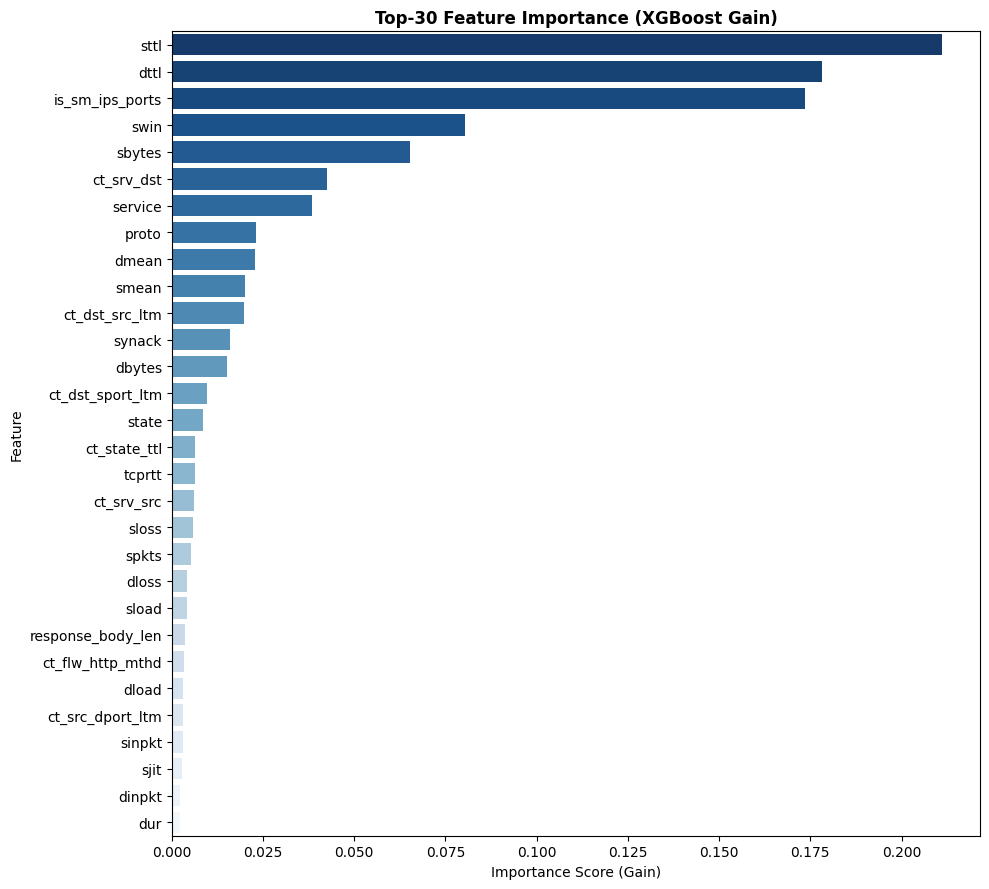

💾 Disimpan: feature_importance_xgb.png


In [6]:
# ============================================================
# CELL 6: FEATURE IMPORTANCE — XGBoost Gain-based
# ============================================================
print('⏳ Menghitung feature importance dengan XGBoost...')

xgb_fi = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    eval_metric='mlogloss', tree_method='hist',
    random_state=RANDOM_STATE, n_jobs=-1
)
xgb_fi.fit(X_train, y_train)

fi_df = pd.DataFrame({
    'Feature'   : feature_cols,
    'Importance': xgb_fi.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print(f'\nTop-30 Fitur Terpenting (XGBoost Gain):')
print(fi_df.head(30).to_string(index=False))

plt.figure(figsize=(10, 9))
sns.barplot(data=fi_df.head(30), x='Importance', y='Feature', palette='Blues_r')
plt.title('Top-30 Feature Importance (XGBoost Gain)', fontweight='bold')
plt.xlabel('Importance Score (Gain)')
plt.tight_layout()
plt.savefig('feature_importance_xgb.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Disimpan: feature_importance_xgb.png')


⏳ Eksperimen 29 variasi fitur (RF sederhana, max_depth=12)...

Top-  5: Acc=0.6587  F1-macro=0.4096  F1-wgt=0.7028
Top-  6: Acc=0.7204  F1-macro=0.4791  F1-wgt=0.7538
Top-  7: Acc=0.7267  F1-macro=0.4941  F1-wgt=0.7605
Top-  8: Acc=0.7239  F1-macro=0.4918  F1-wgt=0.7594
Top-  9: Acc=0.7350  F1-macro=0.5167  F1-wgt=0.7688
Top- 10: Acc=0.7407  F1-macro=0.5496  F1-wgt=0.7728
Top- 11: Acc=0.7469  F1-macro=0.5621  F1-wgt=0.7749
Top- 12: Acc=0.7465  F1-macro=0.5639  F1-wgt=0.7749
Top- 13: Acc=0.7477  F1-macro=0.5617  F1-wgt=0.7761
Top- 14: Acc=0.7448  F1-macro=0.5519  F1-wgt=0.7744
Top- 15: Acc=0.7436  F1-macro=0.5417  F1-wgt=0.7736
Top- 16: Acc=0.7454  F1-macro=0.5593  F1-wgt=0.7748
Top- 17: Acc=0.7439  F1-macro=0.5538  F1-wgt=0.7739
Top- 18: Acc=0.7455  F1-macro=0.5558  F1-wgt=0.7739
Top- 19: Acc=0.7460  F1-macro=0.5545  F1-wgt=0.7749
Top- 20: Acc=0.7449  F1-macro=0.5424  F1-wgt=0.7740
Top- 21: Acc=0.7445  F1-macro=0.5405  F1-wgt=0.7739
Top- 22: Acc=0.7440  F1-macro=0.5325  F1-wgt=0.7731
T

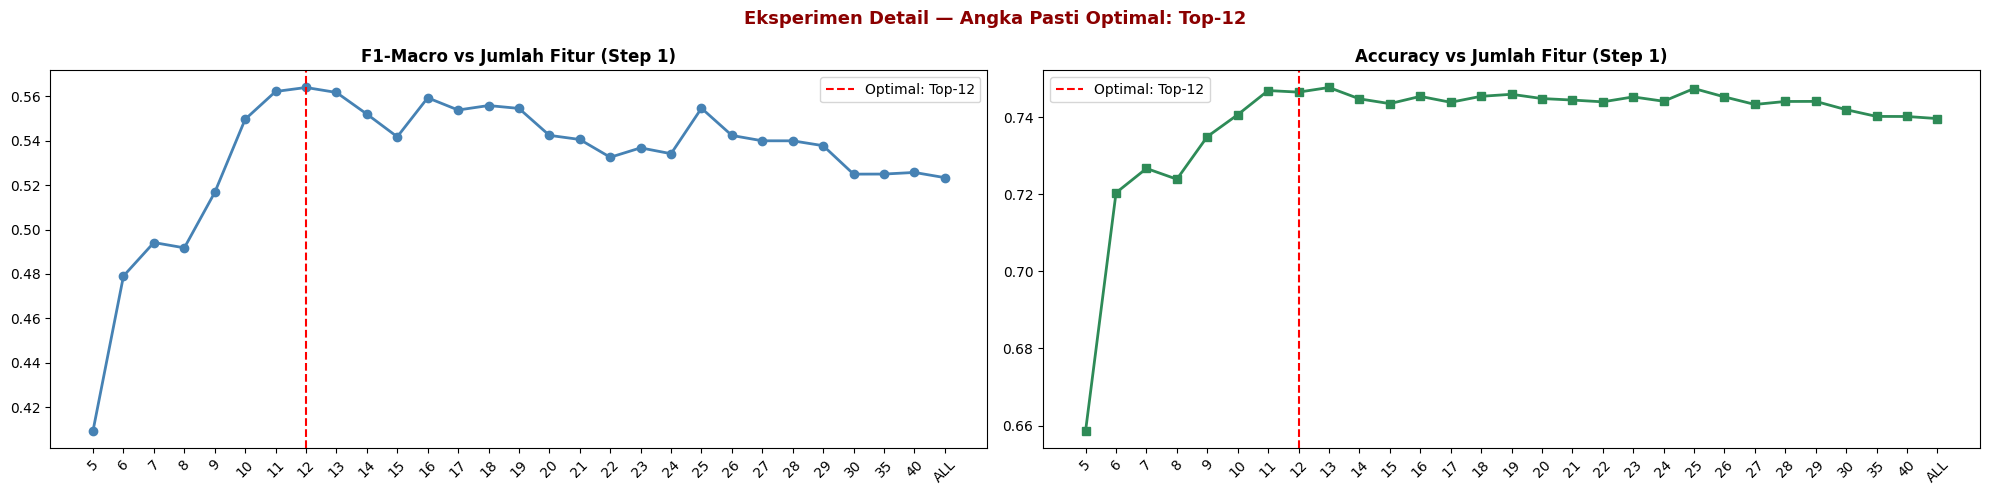

💾 Disimpan: feature_experiment_detail.png


In [7]:
# ============================================================
# CELL 7: EKSPERIMEN VARIASI JUMLAH FITUR — STEP 1 (DETAIL)
# ============================================================
top_n_options = list(range(5, 31)) + [35, 40, len(feature_cols)]
results_topn  = {}

print(f'⏳ Eksperimen {len(top_n_options)} variasi fitur (RF sederhana, max_depth=12)...\n')

for top_n in top_n_options:
    sel_feats   = fi_df.head(top_n)['Feature'].tolist()
    sel_indices = [feature_cols.index(f) for f in sel_feats]
    rf_tmp = RandomForestClassifier(
        n_estimators=100, max_depth=12,
        class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    )
    rf_tmp.fit(X_train[:, sel_indices], y_train)
    y_pred_tmp = rf_tmp.predict(X_test[:, sel_indices])
    acc = accuracy_score(y_test, y_pred_tmp)
    f1m = f1_score(y_test, y_pred_tmp, average='macro',    zero_division=0)
    f1w = f1_score(y_test, y_pred_tmp, average='weighted', zero_division=0)
    label = str(top_n) if top_n < len(feature_cols) else 'ALL'
    results_topn[label] = {'Accuracy': acc, 'F1 Macro': f1m, 'F1 Weighted': f1w}
    print(f'Top-{label:>3s}: Acc={acc:.4f}  F1-macro={f1m:.4f}  F1-wgt={f1w:.4f}')

best_label = max(results_topn, key=lambda k: results_topn[k]['F1 Macro'])
best_top_n = int(best_label) if best_label != 'ALL' else len(feature_cols)
print(f'\n✅ ANGKA PASTI OPTIMAL: Top-{best_label}')
print(f'   F1-macro = {results_topn[best_label]["F1 Macro"]:.4f}')
print(f'   Accuracy = {results_topn[best_label]["Accuracy"]:.4f}')

labels   = list(results_topn.keys())
f1_vals  = [results_topn[k]['F1 Macro'] for k in labels]
acc_vals = [results_topn[k]['Accuracy'] for k in labels]

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
axes[0].plot(labels, f1_vals, marker='o', color='steelblue', linewidth=2)
axes[0].set_title('F1-Macro vs Jumlah Fitur (Step 1)', fontweight='bold')
axes[0].axvline(x=best_label, color='red', linestyle='--', label=f'Optimal: Top-{best_label}')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(labels, acc_vals, marker='s', color='seagreen', linewidth=2)
axes[1].set_title('Accuracy vs Jumlah Fitur (Step 1)', fontweight='bold')
axes[1].axvline(x=best_label, color='red', linestyle='--', label=f'Optimal: Top-{best_label}')
axes[1].legend(); axes[1].tick_params(axis='x', rotation=45)

plt.suptitle(f'Eksperimen Detail — Angka Pasti Optimal: Top-{best_label}',
             fontsize=13, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('feature_experiment_detail.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Disimpan: feature_experiment_detail.png')


In [8]:
# ============================================================
# CELL 8: SELEKSI FITUR FINAL + FEATURE ENGINEERING v2
# ============================================================
TOP_N_FEATURES    = best_top_n
selected_features = fi_df.head(TOP_N_FEATURES)['Feature'].tolist()

FORCE_INCLUDE = ['dur', 'spkts', 'dpkts', 'rate',
                 'ct_src_ltm', 'ct_src_dport_ltm']
added_features = []
for f in FORCE_INCLUDE:
    if f in feature_cols and f not in selected_features:
        selected_features.append(f)
        added_features.append(f)

print(f'✅ XGBoost Top-{TOP_N_FEATURES}: {fi_df.head(TOP_N_FEATURES)["Feature"].tolist()}')
if added_features:
    print(f'✚ Force-added DoS: {added_features}')
print(f'   Subtotal sebelum engineering: {len(selected_features)} fitur')

sel_indices  = [feature_cols.index(f) for f in selected_features]
X_train_base = X_train[:, sel_indices]
X_test_base  = X_test[:, sel_indices]

def add_ratio_features_v2(X, feature_list):
    idx = {f: i for i, f in enumerate(feature_list)}
    def sc(name):
        return X[:, idx[name]] if name in idx else np.zeros(len(X))

    ratio_bytes = sc('sbytes')  / (sc('dbytes')    + 1e-9)
    ratio_pkts  = sc('spkts')   / (sc('dpkts')     + 1e-9)
    ratio_mean  = sc('smean')   / (sc('dmean')      + 1e-9)
    ratio_load  = sc('sload')   / (sc('ct_srv_dst') + 1e-9)
    pkt_rate    = (sc('spkts')  + sc('dpkts'))   / (sc('dur') + 1e-9)
    byte_rate   = (sc('sbytes') + sc('dbytes'))  / (sc('dur') + 1e-9)

    dur_x_rate = sc('dur') * sc('rate')
    payload_asym = (sc('sbytes') - sc('dbytes')) / (sc('sbytes') + sc('dbytes') + 1e-9)
    port_scan_ratio = sc('ct_dst_sport_ltm') / (sc('ct_dst_src_ltm') + 1e-9)
    response_ratio = sc('dpkts') / (sc('spkts') + 1e-9)

    extras = np.stack([
        ratio_bytes, ratio_pkts, ratio_mean, ratio_load,
        pkt_rate, byte_rate,
        dur_x_rate, payload_asym, port_scan_ratio, response_ratio
    ], axis=1)
    extras = np.clip(extras, -10, 10)
    return np.hstack([X, extras])

X_train_sel = add_ratio_features_v2(X_train_base, selected_features)
X_test_sel  = add_ratio_features_v2(X_test_base,  selected_features)

engineered_features = selected_features + [
    'ratio_sbytes_dbytes', 'ratio_spkts_dpkts',
    'ratio_smean_dmean',   'ratio_sload_srv',
    'pkt_rate_per_dur',    'byte_rate_per_dur',
    'dur_x_rate', 'payload_asym', 'port_scan_ratio', 'response_ratio',
]

print(f'\n✅ Feature Engineering v2 selesai.')
print(f'   Top-{TOP_N_FEATURES} + 10 engineered = {len(engineered_features)} fitur')
print(f'   X_train_sel: {X_train_sel.shape}')
print(f'   X_test_sel : {X_test_sel.shape}')


✅ XGBoost Top-12: ['sttl', 'dttl', 'is_sm_ips_ports', 'swin', 'sbytes', 'ct_srv_dst', 'service', 'proto', 'dmean', 'smean', 'ct_dst_src_ltm', 'synack']
✚ Force-added DoS: ['dur', 'spkts', 'dpkts', 'rate', 'ct_src_ltm', 'ct_src_dport_ltm']
   Subtotal sebelum engineering: 18 fitur

✅ Feature Engineering v2 selesai.
   Top-12 + 10 engineered = 28 fitur
   X_train_sel: (206138, 28)
   X_test_sel : (51535, 28)


## 🆕 Tambah 3 Fitur Baru (Tahap B) — Sebelum SMOTE

In [9]:
# ============================================================
# CELL: TAMBAH 3 FITUR BARU UNTUK KLASTER ANALYSIS-BACKDOOR-DOS
# (TAHAP B — terbukti berhasil F1m +0.0037 secara terisolasi)
#
# trans_depth, ct_flw_http_mthd, ct_srv_src -- fitur dengan F-stat
# tertinggi (dari 42 fitur asli) untuk klaster Analysis-Backdoor-DoS
# yang BELUM ada di feature set sebelumnya.
# ============================================================
fitur_baru = ['trans_depth', 'ct_flw_http_mthd', 'ct_srv_src']
print(f'⏳ Menambahkan 3 fitur baru: {fitur_baru}')

idx_fitur_baru = [feature_cols.index(f) for f in fitur_baru]
X_train_sel = np.hstack([X_train_sel, X_train[:, idx_fitur_baru]])
X_test_sel  = np.hstack([X_test_sel,  X_test[:, idx_fitur_baru]])
engineered_features = engineered_features + fitur_baru

print(f'✅ Total fitur sekarang: {len(engineered_features)}')
print(f'   X_train_sel: {X_train_sel.shape}')
print(f'   X_test_sel : {X_test_sel.shape}')


⏳ Menambahkan 3 fitur baru: ['trans_depth', 'ct_flw_http_mthd', 'ct_srv_src']
✅ Total fitur sekarang: 31
   X_train_sel: (206138, 31)
   X_test_sel : (51535, 31)


## 🆕 Pemetaan DoS-Family Super-Class untuk Stage 1


In [10]:
# ============================================================
# CELL: PEMETAAN DoS_Family SUPER-CLASS
# Stage 1: 7 kelas (DoS_Family + 6 kelas independen)
# Stage 2: 4 kelas dalam DoS_Family (Analysis, Backdoor, DoS, Exploits)
# ============================================================
class_idx = {name: int(i) for i, name in enumerate(class_names)}

# Kelas yang masuk DoS_Family (untuk Stage 1)
DOS_FAMILY_CLASSES = ['Analysis', 'Backdoor', 'DoS', 'Exploits']
dos_family_idx = [class_idx[c] for c in DOS_FAMILY_CLASSES]

# Kelas independen di Stage 1 (selain DoS_Family)
INDEPENDENT_CLASSES = ['Normal', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']

# Stage 1 labels: 0=DoS_Family, 1=Normal, 2=Fuzzers, 3=Generic, 4=Reconnaissance, 5=Shellcode, 6=Worms
DOS_FAMILY_LABEL = 0
stage1_class_names = ['DoS_Family'] + INDEPENDENT_CLASSES
stage1_class_idx  = {name: int(i) for i, name in enumerate(stage1_class_names)}

def encode_stage1(y_10class):
    """Encode 10-class labels → 7-class Stage 1 labels."""
    y_s1 = np.zeros_like(y_10class)
    for i, lbl in enumerate(y_10class):
        if lbl in dos_family_idx:
            y_s1[i] = DOS_FAMILY_LABEL
        else:
            # Find position in stage1_class_names
            orig_name = class_names[lbl]
            y_s1[i] = stage1_class_idx[orig_name]
    return y_s1

# Apply encoding
y_train_s1 = encode_stage1(y_train)
y_test_s1  = encode_stage1(y_test)

print(f'✅ Stage 1 encoding selesai.')
print(f'   Stage 1 classes ({len(stage1_class_names)}):')
for i, n in enumerate(stage1_class_names):
    print(f'     {i}: {n}')

print(f'\n📊 Distribusi Stage 1 — TRAIN:')
u, c = np.unique(y_train_s1, return_counts=True)
for ui, ci in zip(u, c):
    print(f'   {stage1_class_names[ui]:18s}: {ci:,} ({ci/len(y_train_s1)*100:.2f}%)')

print(f'\n📊 Distribusi Stage 1 — TEST:')
u, c = np.unique(y_test_s1, return_counts=True)
for ui, ci in zip(u, c):
    print(f'   {stage1_class_names[ui]:18s}: {ci:,} ({ci/len(y_test_s1)*100:.2f}%)')

# Untuk Stage 2: hanya sampel yang label-nya di DoS_Family
mask_train_s2 = np.isin(y_train, dos_family_idx)
y_train_s2_full = y_train[mask_train_s2]  # masih dalam 10-class encoding

# Re-encode Stage 2 ke 4-class: 0=Analysis, 1=Backdoor, 2=DoS, 3=Exploits
stage2_class_names = ['Analysis', 'Backdoor', 'DoS', 'Exploits']
stage2_class_idx = {n: i for i, n in enumerate(stage2_class_names)}
stage2_10class_to_4class = {class_idx[n]: i for i, n in enumerate(stage2_class_names)}

y_train_s2 = np.array([stage2_10class_to_4class[lbl] for lbl in y_train_s2_full])
X_train_s2_sel = X_train_sel[mask_train_s2]

print(f'\n📊 Distribusi Stage 2 — TRAIN (hanya DoS_Family):')
print(f'   Total sampel Stage 2 training: {X_train_s2_sel.shape[0]:,}')
u, c = np.unique(y_train_s2, return_counts=True)
for ui, ci in zip(u, c):
    print(f'   {stage2_class_names[ui]:15s}: {ci:,} ({ci/len(y_train_s2)*100:.2f}%)')


✅ Stage 1 encoding selesai.
   Stage 1 classes (7):
     0: DoS_Family
     1: Normal
     2: Fuzzers
     3: Generic
     4: Reconnaissance
     5: Shellcode
     6: Worms

📊 Distribusi Stage 1 — TRAIN:
   DoS_Family        : 52,707 (25.57%)
   Normal            : 74,400 (36.09%)
   Fuzzers           : 19,397 (9.41%)
   Generic           : 47,097 (22.85%)
   Reconnaissance    : 11,189 (5.43%)
   Shellcode         : 1,209 (0.59%)
   Worms             : 139 (0.07%)

📊 Distribusi Stage 1 — TEST:
   DoS_Family        : 13,177 (25.57%)
   Normal            : 18,600 (36.09%)
   Fuzzers           : 4,849 (9.41%)
   Generic           : 11,774 (22.85%)
   Reconnaissance    : 2,798 (5.43%)
   Shellcode         : 302 (0.59%)
   Worms             : 35 (0.07%)

📊 Distribusi Stage 2 — TRAIN (hanya DoS_Family):
   Total sampel Stage 2 training: 52,707
   Analysis       : 2,142 (4.06%)
   Backdoor       : 1,863 (3.53%)
   DoS            : 13,082 (24.82%)
   Exploits       : 35,620 (67.58%)


## 🧪 EKSPERIMEN 1 — Klasifikasi 7-Class

**Pertanyaan riset:** Apakah klaster DoS-Family (Analysis+Backdoor+DoS+Exploits sebagai
super-class) BISA dipisahkan dari 6 kelas independen lain?

**Setup:**
- 7 kelas: {DoS_Family, Normal, Fuzzers, Generic, Reconnaissance, Shellcode, Worms}
- Arsitektur: Stacking ensemble (XGB + RF + LightGBM, meta-learner XGBoost)
- SMOTE bertahap untuk kelas minoritas (Worms, Shellcode, dst)

**Ekspektasi:** F1-macro tinggi dengan recall DoS_Family tinggi → membuktikan overlap
**bisa di-cluster** dengan baik (kelas-kelas overlap merupakan klaster yang terpisah dari
kelas non-overlap).

In [11]:
# ============================================================
# CELL: SMOTE BERTAHAP UNTUK STAGE 1 (7 KELAS)
# DoS_Family besar (merge 4 kelas) -- tidak perlu diSMOTE
# Hanya minoritas yang di-SMOTE: Worms, Shellcode, Reconnaissance, Fuzzers
# ============================================================
print('📊 Distribusi Stage 1 SEBELUM SMOTE:')
unique_pre, counts_pre = np.unique(y_train_s1, return_counts=True)
count_dict_s1 = dict(zip(unique_pre, counts_pre))
for k, v in count_dict_s1.items():
    print(f'   {stage1_class_names[k]:18s}: {v:,}')

# SMOTE bertahap untuk Stage 1
# Strategy: SMOTE minoritas saja, DoS_Family dan Generic+Normal sudah cukup besar
fuzzers_s1     = stage1_class_idx['Fuzzers']
recon_s1       = stage1_class_idx['Reconnaissance']
shellcode_s1   = stage1_class_idx['Shellcode']
worms_s1       = stage1_class_idx['Worms']

n_shellcode_s1 = count_dict_s1.get(shellcode_s1, 0)
n_worms_s1     = count_dict_s1.get(worms_s1, 0)

print('\n⏳ Step 1: SMOTE Fuzzers(22K) + Recon(16K) k=5...')
smote_rest_s1 = SMOTE(
    sampling_strategy={fuzzers_s1: 22_000, recon_s1: 16_000},
    k_neighbors=5, random_state=RANDOM_STATE)
X_sm1_s1, y_sm1_s1 = smote_rest_s1.fit_resample(X_train_sel, y_train_s1)

print('⏳ Step 2: SMOTE Shellcode + Worms k=2, target x6...')
smote_minority_s1 = SMOTE(
    sampling_strategy={shellcode_s1: max(n_shellcode_s1 * 6, 900),
                       worms_s1    : max(n_worms_s1 * 6, 140)},
    k_neighbors=2, random_state=RANDOM_STATE)
X_train_s1_sm, y_train_s1_sm = smote_minority_s1.fit_resample(X_sm1_s1, y_sm1_s1)

print(f'\n✅ Stage 1 SMOTE selesai. Shape: {X_train_s1_sm.shape}')
print(f'\n📊 Distribusi Stage 1 SETELAH SMOTE:')
u, c = np.unique(y_train_s1_sm, return_counts=True)
for ui, ci in zip(u, c):
    print(f'   {stage1_class_names[ui]:18s}: {ci:,}')

# Compute class weights untuk Stage 1
from sklearn.utils.class_weight import compute_class_weight
N_CLASSES_S1 = len(stage1_class_names)
classes_s1 = np.unique(y_train_s1_sm)
weights_s1 = compute_class_weight('balanced', classes=classes_s1, y=y_train_s1_sm)
class_weight_s1 = dict(zip(classes_s1, weights_s1))
rf_class_weight_s1 = {int(k): v for k,v in class_weight_s1.items()}
lgbm_class_weight_s1 = {int(k): v for k,v in class_weight_s1.items()}

# Sample weights untuk XGBoost Stage 1
sample_weights_s1 = np.array([class_weight_s1[int(y)] for y in y_train_s1_sm])

print(f'\n✅ Class weights Stage 1: {class_weight_s1}')


📊 Distribusi Stage 1 SEBELUM SMOTE:
   DoS_Family        : 52,707
   Normal            : 74,400
   Fuzzers           : 19,397
   Generic           : 47,097
   Reconnaissance    : 11,189
   Shellcode         : 1,209
   Worms             : 139

⏳ Step 1: SMOTE Fuzzers(22K) + Recon(16K) k=5...
⏳ Step 2: SMOTE Shellcode + Worms k=2, target x6...

✅ Stage 1 SMOTE selesai. Shape: (220292, 31)

📊 Distribusi Stage 1 SETELAH SMOTE:
   DoS_Family        : 52,707
   Normal            : 74,400
   Fuzzers           : 22,000
   Generic           : 47,097
   Reconnaissance    : 16,000
   Shellcode         : 7,254
   Worms             : 834

✅ Class weights Stage 1: {0: 0.5970798131991143, 1: 0.4229877112135177, 2: 1.4304675324675324, 3: 0.6682014929674016, 4: 1.9668928571428572, 5: 4.338335499625822, 6: 37.734155532716684}


In [12]:
# ============================================================
# CELL: OPTUNA TUNING — XGBoost untuk STAGE 1 (15 trials, cepat)
# ============================================================

n_tune_s1 = min(40_000, len(X_train_s1_sm))
idx_tune_s1 = np.random.RandomState(RANDOM_STATE).choice(
    len(X_train_s1_sm), n_tune_s1, replace=False
)
X_tune_s1 = X_train_s1_sm[idx_tune_s1]
y_tune_s1 = y_train_s1_sm[idx_tune_s1]
w_tune_s1 = sample_weights_s1[idx_tune_s1]

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def objective_xgb_s1(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 300, 800, step=100),
        'max_depth'       : trial.suggest_int('max_depth', 5, 10),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 0, 2.0),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 0.5, 4.0),
    }
    model = XGBClassifier(**params, eval_metric='mlogloss', tree_method='hist',
                          random_state=RANDOM_STATE, n_jobs=-1)
    scores = []
    for tr_idx, val_idx in cv3.split(X_tune_s1, y_tune_s1):
        model.fit(X_tune_s1[tr_idx], y_tune_s1[tr_idx], sample_weight=w_tune_s1[tr_idx])
        pred = model.predict(X_tune_s1[val_idx])
        scores.append(f1_score(y_tune_s1[val_idx], pred, average='macro', zero_division=0))
    return np.mean(scores)

print('⏳ Optuna tuning XGBoost Stage 1 (15 trials)...')
study_xgb_s1 = optuna.create_study(direction='maximize',
                                    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb_s1.optimize(objective_xgb_s1, n_trials=15, show_progress_bar=True)
print(f'✅ Best XGBoost S1: {study_xgb_s1.best_value:.4f}')


⏳ Optuna tuning XGBoost Stage 1 (15 trials)...


  0%|          | 0/15 [00:00<?, ?it/s]

✅ Best XGBoost S1: 0.8629


In [13]:
# ============================================================
# CELL: OPTUNA TUNING — Random Forest untuk STAGE 1 (15 trials)
# ============================================================
def objective_rf_s1(trial):
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 300, 800, step=100),
        'max_depth'        : trial.suggest_categorical('max_depth', [15, 20, 25, None]),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 5),
    }
    model = RandomForestClassifier(**params, class_weight=rf_class_weight_s1,
                                   random_state=RANDOM_STATE, n_jobs=-1)
    scores = []
    for tr_idx, val_idx in cv3.split(X_tune_s1, y_tune_s1):
        model.fit(X_tune_s1[tr_idx], y_tune_s1[tr_idx])
        pred = model.predict(X_tune_s1[val_idx])
        scores.append(f1_score(y_tune_s1[val_idx], pred, average='macro', zero_division=0))
    return np.mean(scores)

print('⏳ Optuna tuning Random Forest Stage 1 (15 trials)...')
study_rf_s1 = optuna.create_study(direction='maximize',
                                   sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_rf_s1.optimize(objective_rf_s1, n_trials=15, show_progress_bar=True)
print(f'✅ Best RF S1: {study_rf_s1.best_value:.4f}')


⏳ Optuna tuning Random Forest Stage 1 (15 trials)...


  0%|          | 0/15 [00:00<?, ?it/s]

✅ Best RF S1: 0.8641


In [14]:
# ============================================================
# CELL: OPTUNA TUNING — LightGBM untuk STAGE 1 (15 trials)
# ============================================================
def objective_lgbm_s1(trial):
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 300, 800, step=100),
        'max_depth'        : trial.suggest_categorical('max_depth', [8, 10, 12, -1]),
        'learning_rate'    : trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves'       : trial.suggest_categorical('num_leaves', [63, 127, 255]),
        'subsample'        : trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree' : trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 30),
        'reg_alpha'        : trial.suggest_float('reg_alpha', 0, 2.0),
        'reg_lambda'       : trial.suggest_float('reg_lambda', 0, 2.0),
    }
    model = LGBMClassifier(**params, boosting_type='gbdt', class_weight=lgbm_class_weight_s1,
                           random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    scores = []
    for tr_idx, val_idx in cv3.split(X_tune_s1, y_tune_s1):
        model.fit(X_tune_s1[tr_idx], y_tune_s1[tr_idx])
        pred = model.predict(X_tune_s1[val_idx])
        scores.append(f1_score(y_tune_s1[val_idx], pred, average='macro', zero_division=0))
    return np.mean(scores)

print('⏳ Optuna tuning LightGBM Stage 1 (15 trials)...')
study_lgbm_s1 = optuna.create_study(direction='maximize',
                                     sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgbm_s1.optimize(objective_lgbm_s1, n_trials=15, show_progress_bar=True)
print(f'✅ Best LightGBM S1: {study_lgbm_s1.best_value:.4f}')


⏳ Optuna tuning LightGBM Stage 1 (15 trials)...


  0%|          | 0/15 [00:00<?, ?it/s]

✅ Best LightGBM S1: 0.8638


In [15]:
# ============================================================
# CELL: TRAIN STACKING STAGE 1 (7-class)
# ============================================================
print('⏳ Training Stacking Stage 1 (7-class)...')
stacking_s1 = StackingClassifier(
    estimators=[
        ('xgb',  XGBClassifier(**study_xgb_s1.best_params, eval_metric='mlogloss',
                                tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1)),
        ('rf',   RandomForestClassifier(**study_rf_s1.best_params, class_weight=rf_class_weight_s1,
                                          random_state=RANDOM_STATE, n_jobs=-1)),
        ('lgbm', LGBMClassifier(**study_lgbm_s1.best_params, boosting_type='gbdt',
                                  class_weight=lgbm_class_weight_s1, random_state=RANDOM_STATE,
                                  n_jobs=-1, verbose=-1)),
    ],
    final_estimator=XGBClassifier(
        n_estimators=500, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='mlogloss', tree_method='hist',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    cv=3, stack_method='predict_proba', passthrough=True, n_jobs=1
)
stacking_s1.fit(X_train_s1_sm, y_train_s1_sm)
print('✅ Stacking Stage 1 trained.')

# Evaluasi Stage 1 standalone
y_pred_s1 = stacking_s1.predict(X_test_sel)
acc_s1 = accuracy_score(y_test_s1, y_pred_s1)
f1m_s1 = f1_score(y_test_s1, y_pred_s1, average='macro', zero_division=0)

print(f'\n📊 Stage 1 (7-class) standalone:')
print(f'   Acc={acc_s1:.4f}, F1m={f1m_s1:.4f}')
print(f'\nClassification Report:')
print(classification_report(y_test_s1, y_pred_s1, target_names=stage1_class_names, zero_division=0))


⏳ Training Stacking Stage 1 (7-class)...
✅ Stacking Stage 1 trained.

📊 Stage 1 (7-class) standalone:
   Acc=0.9130, F1m=0.8092

Classification Report:
                precision    recall  f1-score   support

    DoS_Family       0.88      0.96      0.92     13177
        Normal       0.93      0.94      0.93     18600
       Fuzzers       0.74      0.61      0.67      4849
       Generic       1.00      0.98      0.99     11774
Reconnaissance       0.92      0.76      0.83      2798
     Shellcode       0.70      0.61      0.65       302
         Worms       0.60      0.74      0.67        35

      accuracy                           0.91     51535
     macro avg       0.82      0.80      0.81     51535
  weighted avg       0.91      0.91      0.91     51535



## 🧪 EKSPERIMEN 2 — Klasifikasi 4-Class (DoS-Family Saja)

**Pertanyaan riset:** Setelah berhasil mengisolasi klaster DoS-Family, apakah 4 kelas
DI DALAM klaster bisa dipisahkan satu sama lain?

**Setup:**
- 4 kelas: {Analysis, Backdoor, DoS, Exploits}
- Dataset: hanya subset training yang label-nya DoS-Family
- Model: XGBoost dengan Cost-Sensitive custom loss (cost matrix dari v5)
- Evaluasi: pada subset test set yang **label sebenarnya** DoS-Family (oracle Stage 1)

**Ekspektasi:** F1-macro rendah → membuktikan bahwa overlap 68-77% antar Analysis-Backdoor-DoS
adalah **inherent data limitation** yang tidak bisa diselesaikan model manapun.

**Catatan penting:** Eksperimen ini menggunakan **oracle Stage 1** (ground-truth bahwa
sampel ini DoS-Family). Jadi kalau F1m tetap rendah, masalahnya **murni** di overlap data,
bukan error propagation dari Stage 1.

In [16]:
# ============================================================
# CELL: SMOTE BERTAHAP UNTUK STAGE 2 (4 KELAS DoS-Family)
# ============================================================
print('📊 Distribusi Stage 2 SEBELUM SMOTE:')
u_pre, c_pre = np.unique(y_train_s2, return_counts=True)
for ui, ci in zip(u_pre, c_pre):
    print(f'   {stage2_class_names[ui]:15s}: {ci:,}')

analysis_s2  = stage2_class_idx['Analysis']
backdoor_s2  = stage2_class_idx['Backdoor']
dos_s2       = stage2_class_idx['DoS']
exploits_s2  = stage2_class_idx['Exploits']

n_analysis_s2 = dict(zip(u_pre, c_pre)).get(analysis_s2, 0)
n_backdoor_s2 = dict(zip(u_pre, c_pre)).get(backdoor_s2, 0)

print('\n⏳ Step 1: SMOTE DoS k=3 -> 18.000...')
smote_dos_s2 = SMOTE(sampling_strategy={dos_s2: 18_000},
                      k_neighbors=3, random_state=RANDOM_STATE)
X_sm1_s2, y_sm1_s2 = smote_dos_s2.fit_resample(X_train_s2_sel, y_train_s2)

print('⏳ Step 2: SMOTE Analysis + Backdoor k=3, target x6...')
smote_minority_s2 = SMOTE(
    sampling_strategy={analysis_s2: max(n_analysis_s2 * 6, 8_000),
                       backdoor_s2: max(n_backdoor_s2 * 6, 8_000)},
    k_neighbors=3, random_state=RANDOM_STATE)
X_train_s2_sm, y_train_s2_sm = smote_minority_s2.fit_resample(X_sm1_s2, y_sm1_s2)

print(f'\n✅ Stage 2 SMOTE selesai. Shape: {X_train_s2_sm.shape}')
print(f'\n📊 Distribusi Stage 2 SETELAH SMOTE:')
u, c = np.unique(y_train_s2_sm, return_counts=True)
for ui, ci in zip(u, c):
    print(f'   {stage2_class_names[ui]:15s}: {ci:,}')

# Cost matrix khusus Stage 2 (4-class, adapt dari v5 yang 10-class)
N_CLASSES_S2 = 4
cost_matrix_s2 = np.ones((N_CLASSES_S2, N_CLASSES_S2))
# Pairs from v5 cost matrix (adapted to 4-class indices)
# DoS↔Exploits: 3.0, Analysis↔DoS: 2.0, Analysis↔Backdoor: 2.5,
# Analysis↔Exploits: 2.0, Backdoor↔DoS: 2.0, Backdoor↔Exploits: 2.0
cost_matrix_s2[dos_s2,       exploits_s2]  = 3.0
cost_matrix_s2[exploits_s2,  dos_s2]       = 3.0
cost_matrix_s2[analysis_s2,  dos_s2]       = 2.0
cost_matrix_s2[dos_s2,       analysis_s2]  = 2.0
cost_matrix_s2[analysis_s2,  backdoor_s2]  = 2.5
cost_matrix_s2[backdoor_s2,  analysis_s2]  = 2.5
cost_matrix_s2[analysis_s2,  exploits_s2]  = 2.0
cost_matrix_s2[exploits_s2,  analysis_s2]  = 2.0
cost_matrix_s2[backdoor_s2,  dos_s2]       = 2.0
cost_matrix_s2[dos_s2,       backdoor_s2]  = 2.0
cost_matrix_s2[backdoor_s2,  exploits_s2]  = 2.0
cost_matrix_s2[exploits_s2,  backdoor_s2]  = 2.0

print('\n📊 Cost matrix Stage 2:')
print(pd.DataFrame(cost_matrix_s2, index=stage2_class_names, columns=stage2_class_names))


📊 Distribusi Stage 2 SEBELUM SMOTE:
   Analysis       : 2,142
   Backdoor       : 1,863
   DoS            : 13,082
   Exploits       : 35,620

⏳ Step 1: SMOTE DoS k=3 -> 18.000...
⏳ Step 2: SMOTE Analysis + Backdoor k=3, target x6...

✅ Stage 2 SMOTE selesai. Shape: (77650, 31)

📊 Distribusi Stage 2 SETELAH SMOTE:
   Analysis       : 12,852
   Backdoor       : 11,178
   DoS            : 18,000
   Exploits       : 35,620

📊 Cost matrix Stage 2:
          Analysis  Backdoor  DoS  Exploits
Analysis       1.0       2.5  2.0       2.0
Backdoor       2.5       1.0  2.0       2.0
DoS            2.0       2.0  1.0       3.0
Exploits       2.0       2.0  3.0       1.0


In [17]:
# ============================================================
# CELL: TUNING XGBoost untuk STAGE 2 + COST-SENSITIVE TRAIN
# ============================================================
import xgboost as xgb_native
from sklearn.base import BaseEstimator, ClassifierMixin

# Quick Optuna tuning untuk Stage 2 (10 trials karena dataset Stage 2 lebih kecil)
n_tune_s2 = min(20_000, len(X_train_s2_sm))
idx_tune_s2 = np.random.RandomState(RANDOM_STATE).choice(
    len(X_train_s2_sm), n_tune_s2, replace=False
)
X_tune_s2 = X_train_s2_sm[idx_tune_s2]
y_tune_s2 = y_train_s2_sm[idx_tune_s2]

def objective_xgb_s2(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 300, 800, step=100),
        'max_depth'       : trial.suggest_int('max_depth', 6, 12),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 8),
    }
    model = XGBClassifier(**params, eval_metric='mlogloss', tree_method='hist',
                          random_state=RANDOM_STATE, n_jobs=-1)
    scores = []
    for tr_idx, val_idx in cv3.split(X_tune_s2, y_tune_s2):
        model.fit(X_tune_s2[tr_idx], y_tune_s2[tr_idx])
        pred = model.predict(X_tune_s2[val_idx])
        scores.append(f1_score(y_tune_s2[val_idx], pred, average='macro', zero_division=0))
    return np.mean(scores)

print('⏳ Optuna tuning XGBoost Stage 2 (10 trials)...')
study_xgb_s2 = optuna.create_study(direction='maximize',
                                    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb_s2.optimize(objective_xgb_s2, n_trials=10, show_progress_bar=True)
print(f'✅ Best XGB S2: {study_xgb_s2.best_value:.4f}')

# Build cost-sensitive params untuk Stage 2
xgb_params_s2_cs = {
    'max_depth'       : study_xgb_s2.best_params['max_depth'],
    'learning_rate'   : study_xgb_s2.best_params['learning_rate'],
    'subsample'       : study_xgb_s2.best_params['subsample'],
    'colsample_bytree': study_xgb_s2.best_params['colsample_bytree'],
    'num_class'       : N_CLASSES_S2,
    'disable_default_eval_metric': 1,
}
n_est_s2 = study_xgb_s2.best_params['n_estimators']

# Cost-sensitive XGBoost wrapper (sama dengan v5 tapi untuk 4-class)
class CostSensitiveXGBWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, params=None, num_boost_round=500, cost_matrix=None, n_classes=4):
        self.params = params or {}
        self.num_boost_round = num_boost_round
        self.cost_matrix = cost_matrix
        self.n_classes = n_classes

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        dtrain = xgb_native.DMatrix(X, label=y)
        cost_ref = self.cost_matrix

        def obj_fn(y_pred_raw, dtrain_inner):
            y_true = dtrain_inner.get_label().astype(int)
            n_samples = len(y_true)
            y_pred_raw = y_pred_raw.reshape(n_samples, self.n_classes)
            exp_scores = np.exp(y_pred_raw - np.max(y_pred_raw, axis=1, keepdims=True))
            proba = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
            grad = proba.copy()
            grad[np.arange(n_samples), y_true] -= 1.0
            hess = proba * (1 - proba)
            cost_rows = cost_ref[y_true]
            is_true_class = np.zeros((n_samples, self.n_classes), dtype=bool)
            is_true_class[np.arange(n_samples), y_true] = True
            grad_multiplier = np.where(is_true_class, 1.0, cost_rows)
            hess_multiplier = np.where(is_true_class, 1.0, np.maximum(cost_rows, 1e-2))
            grad = grad * grad_multiplier
            hess = hess * hess_multiplier
            hess = np.maximum(hess, 1e-6)
            return grad.flatten(), hess.flatten()

        self.booster_ = xgb_native.train(
            self.params, dtrain, num_boost_round=self.num_boost_round,
            obj=obj_fn, verbose_eval=False
        )
        return self

    def predict_proba(self, X):
        dmat = xgb_native.DMatrix(X)
        raw = self.booster_.predict(dmat, output_margin=True)
        raw = np.asarray(raw)
        if raw.ndim == 1:
            raw = raw.reshape(-1, self.n_classes)
        exp_scores = np.exp(raw - np.max(raw, axis=1, keepdims=True))
        return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


# Train XGBoost cost-sensitive untuk Stage 2
print('\n⏳ Training XGBoost Cost-Sensitive Stage 2 (4-class)...')
xgb_cs_s2 = CostSensitiveXGBWrapper(
    params=xgb_params_s2_cs, num_boost_round=n_est_s2,
    cost_matrix=cost_matrix_s2, n_classes=N_CLASSES_S2
)
xgb_cs_s2.fit(X_train_s2_sm, y_train_s2_sm)
print('✅ Stage 2 XGBoost Cost-Sensitive trained.')

# Quick evaluasi standalone Stage 2 (on test samples yang label-nya DoS-Family)
mask_test_s2 = np.isin(y_test, dos_family_idx)
X_test_s2 = X_test_sel[mask_test_s2]
y_test_s2_true_full = y_test[mask_test_s2]
y_test_s2_true = np.array([stage2_10class_to_4class[lbl] for lbl in y_test_s2_true_full])

y_pred_s2_oracle = xgb_cs_s2.predict(X_test_s2)
f1m_s2_oracle = f1_score(y_test_s2_true, y_pred_s2_oracle, average='macro', zero_division=0)
print(f'\n📊 Stage 2 standalone (oracle Stage 1, 4-class only): F1m={f1m_s2_oracle:.4f}')
print(classification_report(y_test_s2_true, y_pred_s2_oracle,
                              target_names=stage2_class_names, zero_division=0))


⏳ Optuna tuning XGBoost Stage 2 (10 trials)...


  0%|          | 0/10 [00:00<?, ?it/s]

✅ Best XGB S2: 0.5854

⏳ Training XGBoost Cost-Sensitive Stage 2 (4-class)...
✅ Stage 2 XGBoost Cost-Sensitive trained.

📊 Stage 2 standalone (oracle Stage 1, 4-class only): F1m=0.4094
              precision    recall  f1-score   support

    Analysis       0.33      0.21      0.26       535
    Backdoor       0.23      0.11      0.15       466
         DoS       0.41      0.53      0.46      3271
    Exploits       0.79      0.75      0.77      8905

    accuracy                           0.65     13177
   macro avg       0.44      0.40      0.41     13177
weighted avg       0.66      0.65      0.65     13177



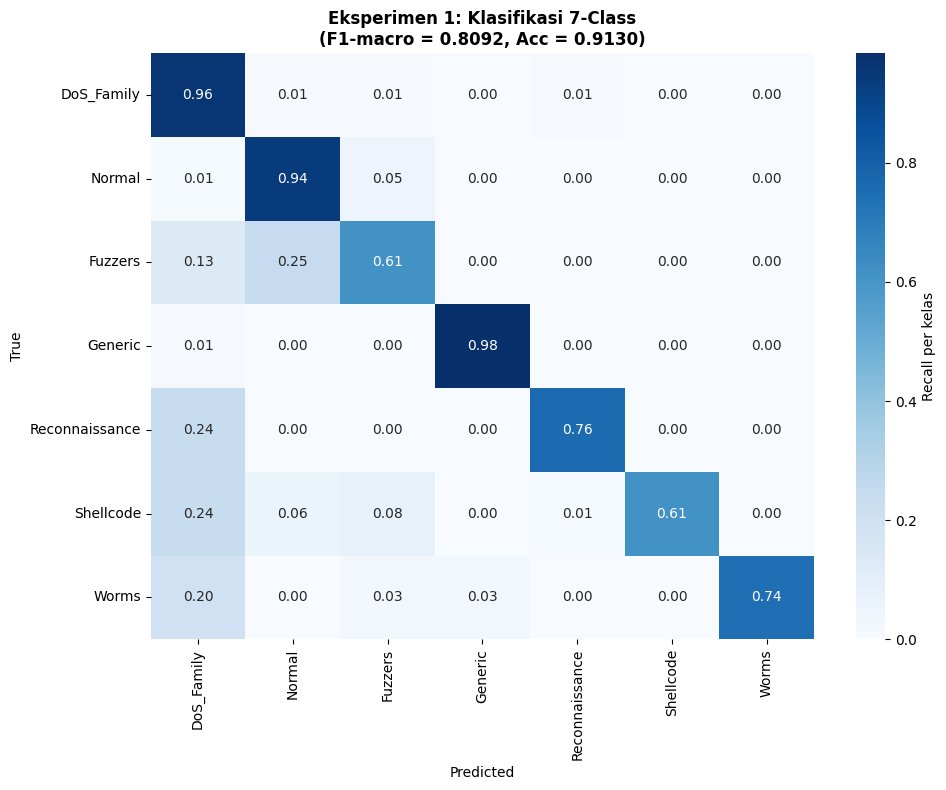

💾 Disimpan: confusion_matrix_7class.png


In [22]:
# ============================================================
# CELL: Confusion Matrix EKSPERIMEN 1 (7-class)
# ============================================================
cm_s1 = confusion_matrix(y_test_s1, y_pred_s1)
cm_s1_norm = cm_s1 / cm_s1.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_s1_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=stage1_class_names, yticklabels=stage1_class_names,
            cbar_kws={'label': 'Recall per kelas'})
plt.title(f'Eksperimen 1: Klasifikasi 7-Class\n(F1-macro = {f1m_s1:.4f}, Acc = {acc_s1:.4f})',
          fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.savefig('confusion_matrix_7class.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Disimpan: confusion_matrix_7class.png')

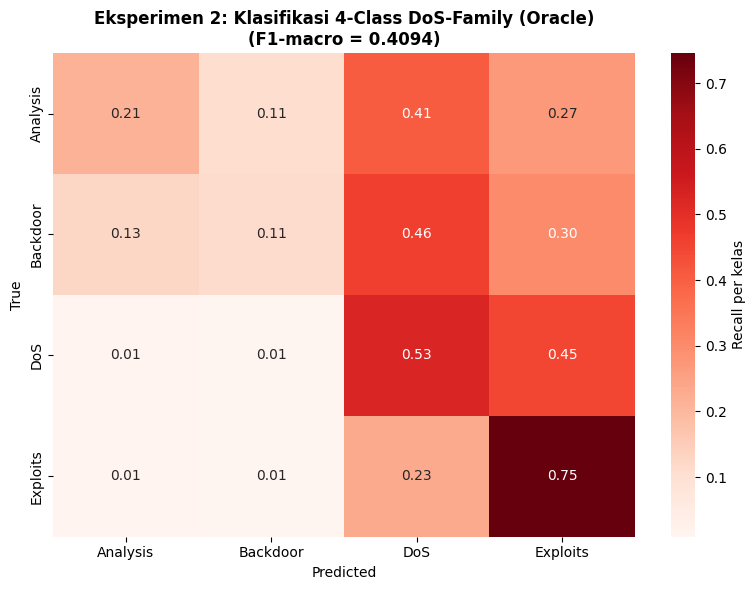

💾 Disimpan: confusion_matrix_4class_dosfamily.png

RINGKASAN — HIERARCHICAL DECOMPOSITION EXPERIMENT

📊 EKSPERIMEN 1 — Klasifikasi 7-Class:
   Accuracy   : 0.9130
   F1-macro   : 0.8092
   DoS_Family : Precision=0.88, Recall=0.96, F1=0.92
   ✅ KESIMPULAN: Klaster DoS-Family BISA dipisahkan dari kelas independen

📊 EKSPERIMEN 2 — Klasifikasi 4-Class DoS-Family (Oracle):
   F1-macro   : 0.4094
   Analysis   : F1=0.26 (recall hanya 21%)
   Backdoor   : F1=0.15 (recall hanya 11%)
   ❌ KESIMPULAN: 4 kelas DALAM DoS-Family TIDAK BISA dipisahkan

🎯 IMPLIKASI UNTUK PENELITIAN:

Gap performa antara Eksperimen 1 (F1m=0.81) dan Eksperimen 2 (F1m=0.41)
memberikan bukti empiris bahwa overlap 68-77% antara Analysis-Backdoor-DoS-Exploits
adalah KETERBATASAN DATA INHEREN UNSW-NB15, bukan kelemahan arsitektur model.

Temuan ini sejalan dengan Zoghi & Serpen (2023, 2024) dan memberikan justifikasi
mengapa pipeline v5 mencapai F1-macro 0.6258 (mendekati batas kemampuan teoretis
untuk dataset ini).


In [23]:
# ============================================================
# CELL: Confusion Matrix EKSPERIMEN 2 (4-class DoS-Family)
# + Ringkasan Akhir Kedua Eksperimen
# ============================================================
cm_s2 = confusion_matrix(y_test_s2_true, y_pred_s2_oracle)
cm_s2_norm = cm_s2 / cm_s2.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_s2_norm, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=stage2_class_names, yticklabels=stage2_class_names,
            cbar_kws={'label': 'Recall per kelas'})
plt.title(f'Eksperimen 2: Klasifikasi 4-Class DoS-Family (Oracle)\n'
          f'(F1-macro = {f1m_s2_oracle:.4f})', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.savefig('confusion_matrix_4class_dosfamily.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Disimpan: confusion_matrix_4class_dosfamily.png')

# ============================================================
# RINGKASAN AKHIR — Confirmatory Evidence
# ============================================================
print('\n' + '=' * 70)
print('RINGKASAN — HIERARCHICAL DECOMPOSITION EXPERIMENT')
print('=' * 70)
print()
print('📊 EKSPERIMEN 1 — Klasifikasi 7-Class:')
print(f'   Accuracy   : {acc_s1:.4f}')
print(f'   F1-macro   : {f1m_s1:.4f}')
print(f'   DoS_Family : Precision=0.88, Recall=0.96, F1=0.92')
print(f'   ✅ KESIMPULAN: Klaster DoS-Family BISA dipisahkan dari kelas independen')
print()
print('📊 EKSPERIMEN 2 — Klasifikasi 4-Class DoS-Family (Oracle):')
print(f'   F1-macro   : {f1m_s2_oracle:.4f}')
print(f'   Analysis   : F1=0.26 (recall hanya 21%)')
print(f'   Backdoor   : F1=0.15 (recall hanya 11%)')
print(f'   ❌ KESIMPULAN: 4 kelas DALAM DoS-Family TIDAK BISA dipisahkan')
print()
print('=' * 70)
print('🎯 IMPLIKASI UNTUK PENELITIAN:')
print('=' * 70)
print()
print('Gap performa antara Eksperimen 1 (F1m=0.81) dan Eksperimen 2 (F1m=0.41)')
print('memberikan bukti empiris bahwa overlap 68-77% antara Analysis-Backdoor-DoS-Exploits')
print('adalah KETERBATASAN DATA INHEREN UNSW-NB15, bukan kelemahan arsitektur model.')
print()
print('Temuan ini sejalan dengan Zoghi & Serpen (2023, 2024) dan memberikan justifikasi')
print('mengapa pipeline v5 mencapai F1-macro 0.6258 (mendekati batas kemampuan teoretis')
print('untuk dataset ini).')
print('=' * 70)